# Analiz

Bu notebook, veri/islenmis/ana_tablo.csv dosyasını kullanarak üç önermeyi test eder.

Analizde kullanılan kütüphaneleri yükleme ve grafiklerin kaydedileceği gorseller klasörünü oluşturma.

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm
from pathlib import Path
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Path("../gorseller").mkdir(exist_ok=True)

## 1. Betimsel istatistikler

Ana tabloyu okuma ve üç önermede kullanılan 8 temel değişkenin betimsel istatistiklerini hesaplama.

In [26]:
ana = pd.read_csv("../veri/islenmis/ana_tablo.csv", encoding="utf-8-sig")
print(ana.shape)
temel = ["farkli_il", "genc_goc_hizi", "yasli_orani", "tek_yasli_payi",
         "hekim_orani", "yatak_orani", "tek_yasli_kadin", "yasam_farki"]
ana[temel].describe().round(2).T

(81, 32)


,count,mean,std,min,25%,50%,75%,max
farkli_il,81.0,19.03,9.69,4.12,11.43,17.77,24.89,40.89
genc_goc_hizi,81.0,-84.98,183.69,-494.69,-181.75,-95.28,41.19,390.72
yasli_orani,81.0,12.79,4.27,3.80,10.07,13.49,15.99,21.66
tek_yasli_payi,81.0,26.15,5.13,8.29,23.60,26.73,29.82,34.32
hekim_orani,81.0,2.12,0.64,1.20,1.67,2.01,2.51,4.57
yatak_orani,81.0,299.70,83.18,130.00,249.00,277.00,327.00,532.00
tek_yasli_kadin,81.0,72.66,3.48,61.05,70.81,73.10,74.99,82.48
yasam_farki,81.0,5.44,0.57,4.10,5.10,5.50,5.70,7.40


## 2. H1'e ilk bakış: Genç göçü ve yalnız yaşlılık

Çocuğu başka ilde olan yalnız yaşlıların oranı ile genç göç hızı ve yaşlı oranı arasındaki korelasyonları hesaplama.

In [27]:
ana[["farkli_il", "genc_goc_hizi", "yasli_orani"]].corr().round(2)

,farkli_il,genc_goc_hizi,yasli_orani
farkli_il,1.00,-0.08,0.72
genc_goc_hizi,-0.08,1.00,0.18
yasli_orani,0.72,0.18,1.00


Genç göç hızı ile çocuğu başka ilde olan yalnız yaşlıların oranını gösteren dağılım grafiğini çizme ve kaydetme.

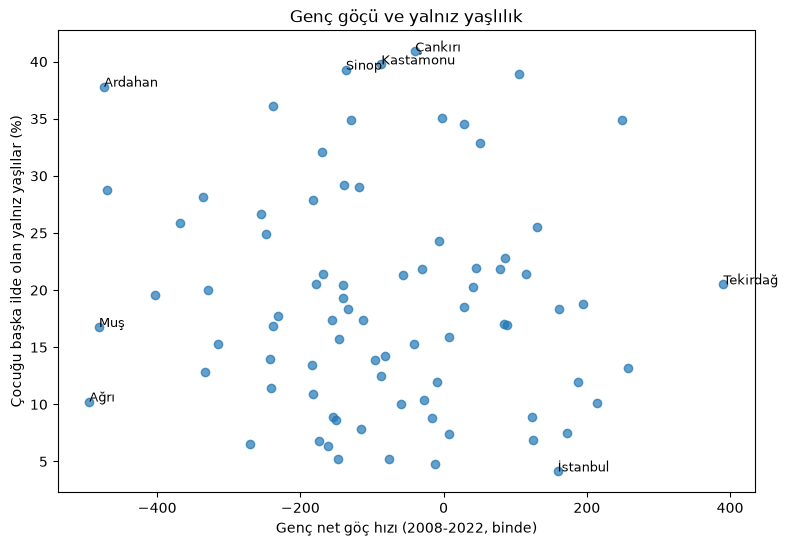

In [28]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(ana["genc_goc_hizi"], ana["farkli_il"], alpha=0.7)
for il in ["Ağrı", "Muş", "Ardahan", "Çankırı", "Sinop", "Kastamonu", "İstanbul", "Tekirdağ"]:
    satir = ana[ana.il_adi == il].iloc[0]
    ax.annotate(il, (satir.genc_goc_hizi, satir.farkli_il), fontsize=9)
ax.set_xlabel("Genç net göç hızı (2008-2022, binde)")
ax.set_ylabel("Çocuğu başka ilde olan yalnız yaşlılar (%)")
ax.set_title("Genç göçü ve yalnız yaşlılık")
fig.savefig("../gorseller/h1_dagilim.png", dpi=200, bbox_inches="tight")
plt.show()

Genç göçü ile çocuğu başka ilde olan yalnız yaşlıların oranı arasında Türkiye genelinde belirgin bir ilişki yoktur (r = −0,08). Bu oran asıl olarak yaşlı oranıyla ilişkilidir (r = 0,72).

## 3. Haritalar

İl sınırlarını okuma ve ana tabloyla, il adı yerine plaka kodu üzerinden birleştirme.

In [29]:
iller = gpd.read_file("../veri/ham/il_sinirlari.geojson")
iller["il_kodu"] = iller["shapeISO"].str[3:].astype(int)
harita = iller.merge(ana, on="il_kodu", how="left", validate="one_to_one")
print(len(harita), harita["farkli_il"].isna().sum())

81 0


Genç göç hızını ve çocuğu başka ilde olan yalnız yaşlıların oranını iki harita üzerinde yan yana gösterme ve kaydetme.

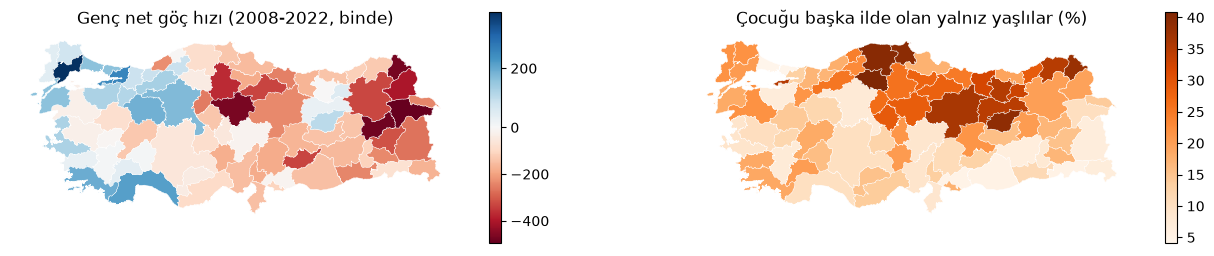

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
harita.plot(column="genc_goc_hizi", cmap="RdBu", norm=TwoSlopeNorm(vcenter=0), legend=True,
            ax=axes[0], edgecolor="white", linewidth=0.3, legend_kwds={"shrink": 0.6})
axes[0].set_title("Genç net göç hızı (2008-2022, binde)")
harita.plot(column="farkli_il", cmap="Oranges", legend=True,
            ax=axes[1], edgecolor="white", linewidth=0.3, legend_kwds={"shrink": 0.6})
axes[1].set_title("Çocuğu başka ilde olan yalnız yaşlılar (%)")
for ax in axes:
    ax.set_axis_off()
fig.savefig("../gorseller/h1_haritalar.png", dpi=200, bbox_inches="tight")
plt.show()

İki haritanın da koyu olduğu bölge İç Anadolu'nun kuzeyi ve doğusudur. Doğu illeri çok genç kaybettiği halde bu oran düşük, Karadeniz illerinde ise yüksektir.

## 4. H1'in testi: Regresyon

Regresyonda kullanılacak iki yardımcı değişkeni (100'e bölünmüş göç hızı ve nüfusun logaritması) oluşturma.

In [31]:
ana["goc_hizi_100"] = ana["genc_goc_hizi"] / 100
ana["log_nufus"] = np.log(ana["toplam_nufus"])

H1 için önceden belirlenen üç regresyon modelini kurma.

In [32]:
m1 = smf.ols("farkli_il ~ goc_hizi_100", data=ana).fit(cov_type="HC3")
m2 = smf.ols("farkli_il ~ goc_hizi_100 + yasli_orani", data=ana).fit(cov_type="HC3")
m3 = smf.ols("farkli_il ~ goc_hizi_100 + yasli_orani + deprem_ili + log_nufus", data=ana).fit(cov_type="HC3")

Üç modelin sonuçlarını tek bir tabloda gösterme.

In [33]:
tablo = summary_col([m1, m2, m3], model_names=["Model 1", "Model 2", "Model 3"],
                    stars=True, float_format="%.3f",
                    info_dict={"N": lambda m: f"{int(m.nobs)}"})
print(tablo)


                Model 1  Model 2   Model 3 
-------------------------------------------
Intercept      18.682*** -4.054** 64.127***
               (1.208)   (1.915)  (9.776)  
goc_hizi_100   -0.414    -1.148** -0.349   
               (0.577)   (0.457)  (0.398)  
yasli_orani              1.729*** 1.295*** 
                         (0.142)  (0.136)  
deprem_ili                        -0.690   
                                  (1.042)  
log_nufus                         -4.652***
                                  (0.667)  
R-squared      0.006     0.568    0.745    
R-squared Adj. -0.006    0.557    0.731    
N              81        81       81       
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


### 4.1 Sağlamlık kontrolü: Sadece 25-34 yaş

Öğrenci yaşları hariç tutulduğunda üniversite şehirlerinin genç göç hızındaki değişimi gösterme.

In [34]:
ana.set_index("il_adi").loc[["Tunceli", "Bayburt", "Erzincan", "Gümüşhane"],
                            ["genc_goc_hizi", "genc2_goc_hizi"]].round(0)

,genc_goc_hizi,genc2_goc_hizi
il_adi,,
Tunceli,105.0,-175.0
Bayburt,51.0,-340.0
Erzincan,29.0,-171.0
Gümüşhane,-3.0,-433.0


Aynı üç modeli yalnızca 25-34 yaş göç hızıyla yeniden kurma.

In [35]:
ana["goc2_hizi_100"] = ana["genc2_goc_hizi"] / 100
s1 = smf.ols("farkli_il ~ goc2_hizi_100", data=ana).fit(cov_type="HC3")
s2 = smf.ols("farkli_il ~ goc2_hizi_100 + yasli_orani", data=ana).fit(cov_type="HC3")
s3 = smf.ols("farkli_il ~ goc2_hizi_100 + yasli_orani + deprem_ili + log_nufus", data=ana).fit(cov_type="HC3")
print(summary_col([s1, s2, s3], model_names=["Model 1", "Model 2", "Model 3"],
                  stars=True, float_format="%.3f",
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))


                Model 1   Model 2   Model 3 
--------------------------------------------
Intercept      17.011*** -3.954**  58.941***
               (1.235)   (1.790)   (12.794) 
goc2_hizi_100  -1.776*** -1.777*** -0.550   
               (0.627)   (0.507)   (0.546)  
yasli_orani              1.639***  1.299*** 
                         (0.131)   (0.136)  
deprem_ili                         -0.552   
                                   (1.018)  
log_nufus                          -4.291***
                                   (0.857)  
R-squared      0.109     0.631     0.748    
R-squared Adj. 0.098     0.622     0.735    
N              81        81        81       
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


Genç göçü, yaşlı oranı kontrol edildiğinde anlamlı hale gelir, nüfus büyüklüğü eklendiğinde ise anlamlılığını kaybeder. Öğrenci yaşları çıkarıldığında (25-34) ilişki daha güçlü görünür.

## 5. Kümeleme: İl tipleri

Kümelemede kullanılacak üç değişkeni seçme ve standartlaştırma.

In [36]:
degiskenler = ["genc2_goc_hizi", "yasli_orani", "farkli_il"]
X = StandardScaler().fit_transform(ana[degiskenler])

2 ile 6 arasındaki küme sayıları için inertia ve silhouette değerlerini karşılaştırma.

In [37]:
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    print(k, round(km.inertia_, 1), round(silhouette_score(X, km.labels_), 3))

2 140.2 0.359
3 100.0 0.325
4 77.3 0.317
5 64.6 0.324
6 54.0 0.339


İlleri üç kümeye ayırma ve her kümenin ortalama profilini hesaplama.

In [38]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
ana["kume"] = km.labels_
profil = ana.groupby("kume")[degiskenler].mean().round(1)
profil["il_sayisi"] = ana["kume"].value_counts()
profil

,genc2_goc_hizi,yasli_orani,farkli_il,il_sayisi
kume,,,,
0,29.8,13.3,15.3,33
1,-202.3,7.6,12.3,23
2,-222.3,16.9,30.2,25


Her kümede yer alan illeri listeleme.

In [39]:
for k in sorted(ana["kume"].unique()):
    print(k, ana.loc[ana["kume"] == k, "il_adi"].tolist())

0 ['Afyonkarahisar', 'Ankara', 'Antalya', 'Aydın', 'Balıkesir', 'Bilecik', 'Burdur', 'Bursa', 'Çanakkale', 'Denizli', 'Eskişehir', 'Isparta', 'Mersin', 'İstanbul', 'İzmir', 'Kayseri', 'Kırklareli', 'Kocaeli', 'Konya', 'Kütahya', 'Malatya', 'Manisa', 'Muğla', 'Nevşehir', 'Sakarya', 'Samsun', 'Tekirdağ', 'Uşak', 'Aksaray', 'Karaman', 'Yalova', 'Osmaniye', 'Düzce']
1 ['Adana', 'Adıyaman', 'Ağrı', 'Bingöl', 'Bitlis', 'Diyarbakır', 'Elazığ', 'Erzurum', 'Gaziantep', 'Hakkari', 'Hatay', 'Kars', 'Kahramanmaraş', 'Mardin', 'Muş', 'Niğde', 'Siirt', 'Şanlıurfa', 'Van', 'Batman', 'Şırnak', 'Iğdır', 'Kilis']
2 ['Amasya', 'Artvin', 'Bolu', 'Çankırı', 'Çorum', 'Edirne', 'Erzincan', 'Giresun', 'Gümüşhane', 'Kastamonu', 'Kırşehir', 'Ordu', 'Rize', 'Sinop', 'Sivas', 'Tokat', 'Trabzon', 'Tunceli', 'Yozgat', 'Zonguldak', 'Bayburt', 'Kırıkkale', 'Bartın', 'Ardahan', 'Karabük']


Kümelere isim verme, kümeleri harita üzerinde gösterme ve haritayı kaydetme.

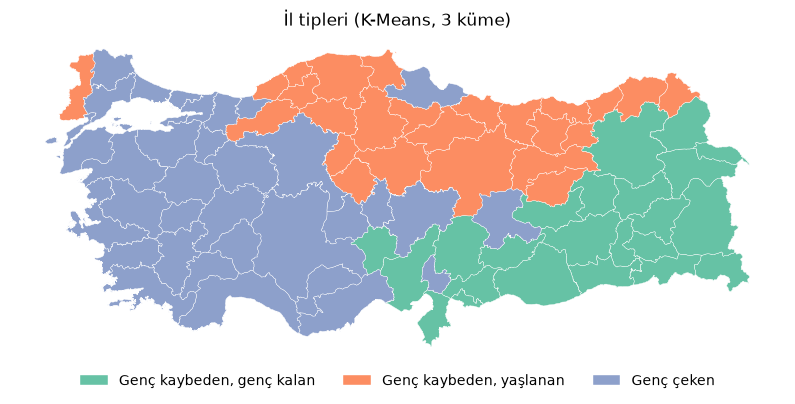

In [40]:
harita["kume"] = harita["il_kodu"].map(ana.set_index("il_kodu")["kume"])
kume_adlari = {0: "Genç çeken", 1: "Genç kaybeden, genç kalan", 2: "Genç kaybeden, yaşlanan"}
ana["kume_adi"] = ana["kume"].map(kume_adlari)
harita["kume_adi"] = harita["kume"].map(kume_adlari)
fig, ax = plt.subplots(figsize=(10, 5))
harita.plot(column="kume_adi", categorical=True, cmap="Set2", legend=True,
            ax=ax, edgecolor="white", linewidth=0.3,
            legend_kwds={"loc": "upper center", "bbox_to_anchor": (0.5, 0),
                         "ncol": 3, "frameon": False})
ax.set_axis_off()
ax.set_title("İl tipleri (K-Means, 3 küme)")
fig.savefig("../gorseller/kumeler_harita.png", dpi=200, bbox_inches="tight")
plt.show()

Algoritma üç bölgesel il tipi bulmuştur. Genç kaybeden iki küme benzer oranda genç kaybetse de, çocuğu başka ilde olan yalnız yaşlıların oranı yaşlanan kümede iki buçuk kat fazladır.

## 6. H2'nin testi: Sağlığa erişim

Yalnız yaşlı göstergeleri ile hekim ve yatak oranları arasındaki korelasyonları hesaplama.

In [41]:
ana[["farkli_il", "tek_yasli_payi", "hekim_orani", "yatak_orani"]].corr().round(2)

,farkli_il,tek_yasli_payi,hekim_orani,yatak_orani
farkli_il,1.00,0.52,-0.09,0.03
tek_yasli_payi,0.52,1.00,0.31,0.34
hekim_orani,-0.09,0.31,1.00,0.74
yatak_orani,0.03,0.34,0.74,1.00


Üç il tipinin hekim ve yatak oranlarını karşılaştırma.

In [42]:
ana.groupby("kume_adi")[["farkli_il", "hekim_orani", "yatak_orani"]].mean().round(2)

,farkli_il,hekim_orani,yatak_orani
kume_adi,,,
"Genç kaybeden, genç kalan",12.27,1.73,263.70
"Genç kaybeden, yaşlanan",30.17,2.18,316.08
Genç çeken,15.31,2.36,312.39


Nüfus büyüklüğünü kontrol ederek yalnız yaşlıların oranı ile hekim ve yatak oranları arasındaki ilişkiyi test etme.

In [43]:
r_hekim = smf.ols("hekim_orani ~ farkli_il + log_nufus", data=ana).fit(cov_type="HC3")
r_yatak = smf.ols("yatak_orani ~ farkli_il + log_nufus", data=ana).fit(cov_type="HC3")
print(summary_col([r_hekim, r_yatak], model_names=["Hekim", "Yatak"],
                  stars=True, float_format="%.3f",
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))


                 Hekim     Yatak  
----------------------------------
Intercept      -4.095*** -312.825*
               (1.332)   (168.846)
farkli_il      0.024***  3.099*** 
               (0.008)   (1.177)  
log_nufus      0.434***  41.627***
               (0.094)   (11.450) 
R-squared      0.244     0.129    
R-squared Adj. 0.225     0.107    
N              81        81       
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


Çocuğu başka ilde olan yalnız yaşlıların oranı yüksek, hekim oranı düşük olan illeri listeleme.

In [44]:
cift = ana[(ana.farkli_il > ana.farkli_il.median()) & (ana.hekim_orani < ana.hekim_orani.median())]
print(len(cift))
cift.sort_values("farkli_il", ascending=False)[["il_adi", "farkli_il", "hekim_orani", "kume_adi"]].head(10).round(2)

21


,il_adi,farkli_il,hekim_orani,kume_adi
17,Çankırı,40.89,1.67,"Genç kaybeden, yaşlanan"
36,Kastamonu,39.76,1.76,"Genç kaybeden, yaşlanan"
56,Sinop,39.29,1.55,"Genç kaybeden, yaşlanan"
74,Ardahan,37.81,1.67,"Genç kaybeden, yaşlanan"
28,Gümüşhane,35.05,1.73,"Genç kaybeden, yaşlanan"
76,Yalova,34.89,1.81,Genç çeken
7,Artvin,34.85,1.67,"Genç kaybeden, yaşlanan"
68,Bayburt,32.86,1.89,"Genç kaybeden, yaşlanan"
65,Yozgat,28.79,1.76,"Genç kaybeden, yaşlanan"
4,Amasya,27.88,1.74,"Genç kaybeden, yaşlanan"


H2 desteklenmemiştir; yalnız yaşlıların çok olduğu iller daha az hekime ya da yatağa sahip değildir. Yine de 21 il hem yalnız yaşlı yoğunluğu hem de görece düşük hekim oranı taşımaktadır.

## 7. H3'ün testi: Yalnız yaşlılığın cinsiyet boyutu

Her ilde yalnız yaşayan yaşlıların çoğunluğunun kadın olup olmadığını kontrol etme ve uç değerdeki illeri gösterme.

In [45]:
print((ana["tek_yasli_kadin"] > 50).all())
ana.sort_values("tek_yasli_kadin")[["il_adi", "tek_yasli_kadin", "kume_adi"]].iloc[[0, 1, 2, -3, -2, -1]].round(1)

True


,il_adi,tek_yasli_kadin,kume_adi
61,Tunceli,61.1,"Genç kaybeden, yaşlanan"
74,Ardahan,65.0,"Genç kaybeden, yaşlanan"
7,Artvin,65.4,"Genç kaybeden, yaşlanan"
14,Burdur,77.9,Genç çeken
62,Şanlıurfa,78.3,"Genç kaybeden, genç kalan"
72,Şırnak,82.5,"Genç kaybeden, genç kalan"


Yalnız yaşlılardaki kadın oranı ile kadın-erkek yaşam süresi farkı arasındaki korelasyonları hesaplama.

In [46]:
ana[["tek_yasli_kadin", "yasam_farki", "yasli_orani", "farkli_il"]].corr().round(2)

,tek_yasli_kadin,yasam_farki,yasli_orani,farkli_il
tek_yasli_kadin,1.00,-0.03,-0.48,-0.72
yasam_farki,-0.03,1.00,0.29,0.23
yasli_orani,-0.48,0.29,1.00,0.72
farkli_il,-0.72,0.23,0.72,1.00


Kadın oranı ile yaşam süresi farkı arasındaki ilişkiyi, deprem bölgesindeki 11 ilin hariç tutulduğu model dahil üç modelle test etme.

In [47]:
k1 = smf.ols("tek_yasli_kadin ~ yasam_farki", data=ana).fit(cov_type="HC3")
k2 = smf.ols("tek_yasli_kadin ~ yasam_farki + yasli_orani + deprem_ili", data=ana).fit(cov_type="HC3")
k3 = smf.ols("tek_yasli_kadin ~ yasam_farki + yasli_orani",
             data=ana[ana.deprem_ili == 0]).fit(cov_type="HC3")
print(summary_col([k1, k2, k3], model_names=["Model 1", "Model 2", "Deprem hariç"],
                  stars=True, float_format="%.3f",
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))


                Model 1   Model 2  Deprem hariç
-----------------------------------------------
Intercept      73.744*** 74.100*** 74.207***   
               (5.379)   (3.673)   (4.670)     
yasam_farki    -0.199    0.710     0.645       
               (1.017)   (0.807)   (1.065)     
yasli_orani              -0.416*** -0.397***   
                         (0.111)   (0.132)     
deprem_ili               0.110                 
                         (0.717)               
R-squared      0.001     0.243     0.199       
R-squared Adj. -0.012    0.213     0.175       
N              81        81        70          
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


Üç il tipinde yalnız yaşlılardaki kadın oranını ve yaşam süresi farkını karşılaştırma.

In [48]:
ana.groupby("kume_adi")[["tek_yasli_kadin", "yasam_farki"]].mean().round(2)

,tek_yasli_kadin,yasam_farki
kume_adi,,
"Genç kaybeden, genç kalan",74.20,5.18
"Genç kaybeden, yaşlanan",69.95,5.67
Genç çeken,73.64,5.45


Her ilde yalnız yaşayan yaşlıların çoğunluğu kadındır, ancak bu durum yaşam süresi farkıyla ilişkili değildir. Göç veren illerde yalnız yaşlılar arasında erkeklerin payı daha yüksektir.

## 8. Bulguların özeti

| Önerme | Sonuç | Temel kanıt |
|---|---|---|
| H1: Genç kaybeden illerde çocuğu başka ilde olan yalnız yaşlılar daha fazladır | Kısmen destekleniyor | Yaşlı oranı kontrol edildiğinde ve öğrenci yaşları çıkarıldığında anlamlı; nüfus büyüklüğü eklendiğinde anlamlı değil. |
| H2: Bu iller sağlık hizmetine daha az erişir | Desteklenmiyor | Korelasyon sıfıra yakın; nüfus kontrol edildiğinde ilişki ters yönde. |
| H3: Yalnız yaşlılık kadınlara özgüdür ve yaşam süresi farkıyla ilişkilidir | Kısmen destekleniyor | Her ilde yalnız yaşlıların çoğunluğu kadın, ancak yaşam süresi farkıyla ilişki yok. |

Aynı göç farklı sonuçlar doğurmaktadır: Doğu ile Karadeniz benzer oranda genç kaybetse de, çocuğu başka ilde olan yalnız yaşlıların oranı Karadeniz'de iki buçuk kat fazladır.